# ЛР1. Анализ датасета SMS Spam Collection

**Направление:** NLP — анализ текста.
**Задача будущей модели:** бинарная классификация SMS-сообщений на `spam` и `ham` (не спам).
**Вход:** текст SMS-сообщения. **Выход:** метка класса и вероятность спама.
**Пользователь:** сервис фильтрации сообщений (оператор связи, мессенджер), который отправляет текст в модель через API.

Содержание ноутбука:
1. Проверка целостности файла данных (SHA256 против эталона).
2. Загрузка и общие характеристики датасета.
3. Распределение классов и оценка сбалансированности.
4. Длина сообщений по классам.
5. Выводы.

In [7]:
import csv
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Ноутбук лежит в notebooks/, корень проекта — на уровень выше
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_FILE = ROOT / "data" / "raw" / "SMSSpamCollection"
REFERENCE = ROOT / "integrity" / "SHA256SUMS"
FIG_DIR = ROOT / "notebooks" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Корень проекта:", ROOT)
print("Файл данных существует:", DATA_FILE.exists())

Корень проекта: /home/mluser/ml-project
Файл данных существует: True


## 1. Проверка целостности

Перед анализом сравниваем SHA256 файла с эталонным значением, сохранённым в `integrity/SHA256SUMS` (эталон хранится отдельно от каталога `data/`). Совпадение показывает, что файл не изменился с момента фиксации эталона, но не доказывает достоверность самого источника.

In [8]:
def sha256_of(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            digest.update(chunk)
    return digest.hexdigest()

actual = sha256_of(DATA_FILE)
print("SHA256 фактический:", actual)

if REFERENCE.exists():
    reference = {}
    for line in REFERENCE.read_text(encoding="utf-8").splitlines():
        if line.strip() and not line.startswith("#"):
            h, name = line.split(maxsplit=1)
            reference[name.lstrip("*")] = h.lower()
    expected = reference.get("data/raw/SMSSpamCollection")
    print("SHA256 эталонный: ", expected)
    print("Целостность подтверждена" if actual == expected else "ВНИМАНИЕ: хэш не совпадает с эталоном!")
else:
    print("Эталон integrity/SHA256SUMS ещё не создан")

SHA256 фактический: 7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d
SHA256 эталонный:  7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d
Целостность подтверждена


## 2. Загрузка и общие характеристики

Файл — TSV без заголовка: `метка<TAB>текст`. Параметр `quoting=csv.QUOTE_NONE` обязателен: в текстах встречаются непарные кавычки, и без него pandas склеивает соседние строки (получается 5 572 строки вместо 5 574).

In [9]:
df = pd.read_csv(DATA_FILE, sep="\t", header=None, names=["label", "text"],
                 quoting=csv.QUOTE_NONE, encoding="utf-8")

print("Размер файла, байт:", DATA_FILE.stat().st_size)
print("Число объектов:", len(df))
print("Столбцы:", list(df.columns))
print("Число классов:", df["label"].nunique(), "->", sorted(df["label"].unique()))
print("Пропуски:", df.isna().sum().to_dict())
print("Полных дубликатов строк:", df.duplicated().sum())
df.head()

Размер файла, байт: 477907
Число объектов: 5574
Столбцы: ['label', 'text']
Число классов: 2 -> ['ham', 'spam']
Пропуски: {'label': 0, 'text': 0}
Полных дубликатов строк: 403


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 3. Распределение классов

In [10]:
counts = df["label"].value_counts()
shares = df["label"].value_counts(normalize=True) * 100
summary = pd.DataFrame({"count": counts, "share_%": shares.round(2)})
print(summary)
print(f"\nСоотношение ham : spam = {counts['ham'] / counts['spam']:.2f} : 1")
print(f"Разница в числе объектов: {counts['ham'] - counts['spam']}")
print(f"Accuracy константного классификатора (всегда 'ham'): {shares['ham']:.2f} %")

       count  share_%
label                
ham     4827     86.6
spam     747     13.4

Соотношение ham : spam = 6.46 : 1
Разница в числе объектов: 4080
Accuracy константного классификатора (всегда 'ham'): 86.60 %


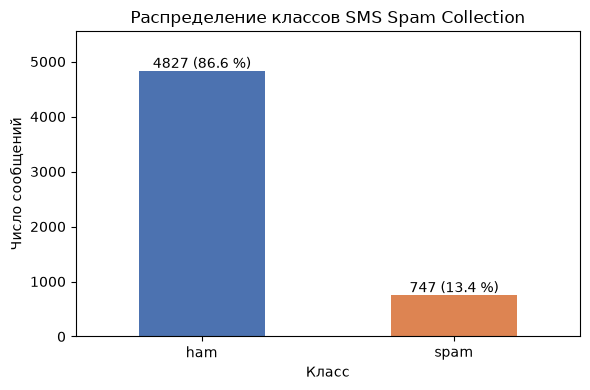

In [11]:
ax = counts.plot(kind="bar", color=["#4C72B0", "#DD8452"], rot=0, figsize=(6, 4))
ax.set_title("Распределение классов SMS Spam Collection")
ax.set_xlabel("Класс")
ax.set_ylabel("Число сообщений")
for i, (n, s) in enumerate(zip(counts, shares)):
    ax.text(i, n + 60, f"{n} ({s:.1f} %)", ha="center")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.savefig(FIG_DIR / "class_distribution.png", dpi=150)
plt.show()

## 4. Длина сообщений по классам

        count   mean   std   min    25%    50%    75%    max
label                                                       
ham    4827.0   71.5  58.3   2.0   33.0   52.0   93.0  910.0
spam    747.0  138.7  28.9  13.0  133.0  149.0  157.0  223.0


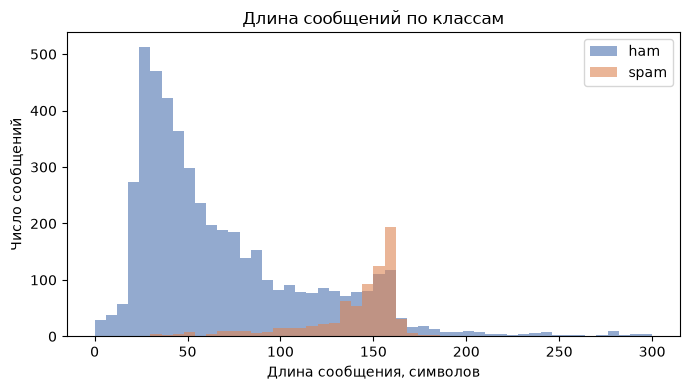

In [12]:
df["length"] = df["text"].str.len()
print(df.groupby("label")["length"].describe().round(1))

fig, ax = plt.subplots(figsize=(7, 4))
for label, color in [("ham", "#4C72B0"), ("spam", "#DD8452")]:
    ax.hist(df.loc[df["label"] == label, "length"], bins=50, range=(0, 300),
            alpha=0.6, label=label, color=color)
ax.set_title("Длина сообщений по классам")
ax.set_xlabel("Длина сообщения, символов")
ax.set_ylabel("Число сообщений")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "message_length.png", dpi=150)
plt.show()

## 5. Выводы

* Датасет **несбалансирован**: класс `ham` составляет около 86,6 % объектов, `spam` — около 13,4 % (соотношение ≈ 6,5 : 1).
* Константный классификатор «всегда ham» уже даёт accuracy ≈ 86,6 %, поэтому **accuracy не подходит как основная метрика**. В следующих работах следует использовать precision, recall и F1 для класса `spam`, матрицу ошибок и стратифицированное разбиение на train/test.
* При обучении модель будет смещена в сторону мажоритарного класса и может пропускать спам (ошибки II рода). Это можно компенсировать весами классов (`class_weight="balanced"`) или выбором порога, не меняя сам датасет.
* В датасете есть дубликаты сообщений (403). При разбиении их нужно учитывать, чтобы одинаковые тексты не попали одновременно в train и test (утечка данных).
* Спам-сообщения в среднем заметно длиннее обычных — длина текста является информативным признаком.